# Moroccan Legal RAG — VLM OCR Correction Benchmark

## Objective
Test Qwen2.5-VL 3B as:
1. **Direct transcriber** — extract text from legal page images
2. **OCR corrector** — fix errors in Tesseract/EasyOCR output using visual verification

Compare against Tesseract and EasyOCR baselines on CER/WER and article preservation accuracy.

## Setup
- Model: Qwen2.5-VL-3B-Instruct
- GPU: T4 (16GB VRAM)
- Test pages: from uploaded Moroccan legal PDFs

In [1]:
# System deps
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ara tesseract-ocr-fra poppler-utils

# Python packages
!pip install -q transformers accelerate bitsandbytes sentencepiece qwen-vl-utils
!pip install -q pytesseract pdf2image pymupdf Pillow matplotlib pandas

# PyTorch memory optimization
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

print("All dependencies installed.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
All dependencies installed.


In [2]:
import torch
import numpy as np
import pandas as pd
import time
import re
import json
from PIL import Image
import pytesseract
from pdf2image import convert_from_path
from pathlib import Path
import matplotlib.pyplot as plt

print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # print(f"VRAM: {torch.cuda.get_device_properties(0).total_mem / 1024**3:.1f} GB")

PyTorch: 2.10.0+cu128
CUDA: True
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:

from google.colab import files

TEST_DIR = Path("/content/drive/MyDrive/Data Legal/test")
# TEST_DIR.mkdir(exist_ok=True)

# print("Upload your Moroccan legal PDFs (same set as before):")
# uploaded = files.upload()

# for filename, content in uploaded.items():
#     dest = TEST_DIR / filename
#     with open(dest, "wb") as f:
#         f.write(content)
#     print(f"Saved: {filename}")

pdf_files = sorted(TEST_DIR.glob("*.pdf"))
print(f"\nFiles: {len(pdf_files)}")
for f in pdf_files:
    print(f"  {f.name}")


Files: 4
  Livret 2.pdf
  code_route.pdf
  ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  مدونة الأسرة1.pdf


Converting: Livret 2.pdf
  2 pages
Converting: code_route.pdf
  2 pages
Converting: ظهير شريف رقم 1.10.07 صادر في 26 من صفر 1431 (11 فبراير 2010) بتنفيذ القانون رقم 52.05 المتعلق بمدونة السير على الطرق.pdf
  2 pages
Converting: مدونة الأسرة1.pdf
  2 pages

Total test pages: 8


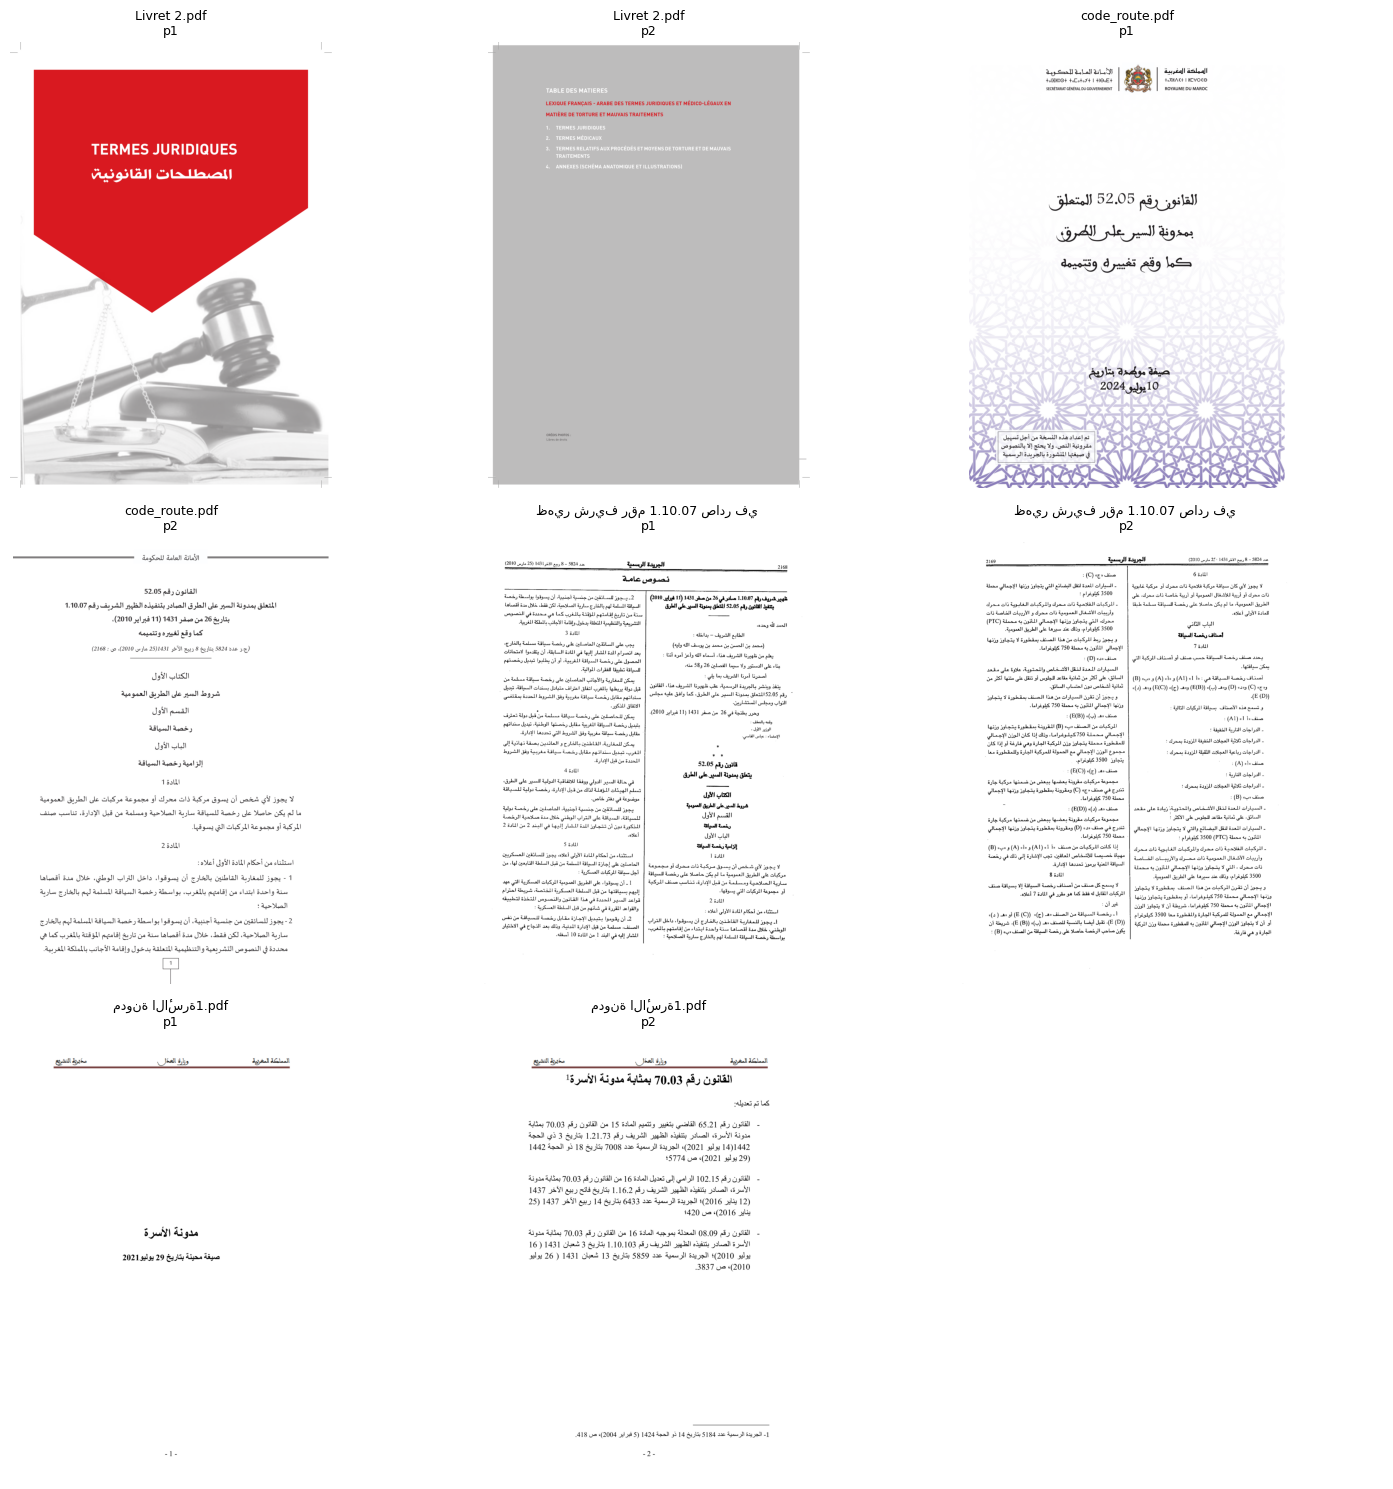

In [5]:
test_pages = []

for pdf_path in pdf_files:
    print(f"Converting: {pdf_path.name}")
    try:
        images = convert_from_path(pdf_path, dpi=200, first_page=1, last_page=2)  # lower DPI to reduce memory
        for i, img in enumerate(images):
            test_pages.append({
                "source": pdf_path.name,
                "page_num": i + 1,
                "image": img,
            })
        print(f"  {len(images)} pages")
    except Exception as e:
        print(f"  Error: {e}")

print(f"\nTotal test pages: {len(test_pages)}")

# Show pages
n = len(test_pages)
cols = min(n, 3)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
if rows == 1 and cols == 1:
    axes = [axes]
elif rows == 1:
    axes = axes.flatten()
else:
    axes = axes.flatten()
for i, page in enumerate(test_pages):
    axes[i].imshow(page["image"])
    axes[i].set_title(f"{page['source'][:30]}\np{page['page_num']}", fontsize=9)
    axes[i].axis('off')
for j in range(n, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [6]:
TESS_CONFIG = r'--oem 3 --psm 6 -l ara+fra'

def basic_clean(text):
    if not text:
        return ""
    text = re.sub(r'[\u200b-\u200f\u202a-\u202e\u2060-\u2069]', '', text)
    text = re.sub(r'[أإآ]', 'ا', text)
    text = re.sub(r'ـ+', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

print("Running Tesseract OCR...")
for page in test_pages:
    start = time.time()
    raw = pytesseract.image_to_string(page["image"], config=TESS_CONFIG)
    page["tess_raw"] = raw
    page["tess_text"] = basic_clean(raw)
    page["tess_time"] = time.time() - start
    arabic = sum(1 for c in page["tess_text"] if '\u0600' <= c <= '\u06ff')
    print(f"  {page['source'][:30]} p{page['page_num']}: {len(page['tess_text'])} chars, {arabic} Arabic, {page['tess_time']:.1f}s")
print("Tesseract baseline complete.")

Running Tesseract OCR...
  Livret 2.pdf p1: 41 chars, 18 Arabic, 2.4s
  Livret 2.pdf p2: 160 chars, 20 Arabic, 6.8s
  code_route.pdf p1: 95 chars, 53 Arabic, 4.2s
  code_route.pdf p2: 921 chars, 702 Arabic, 8.2s
  ظهير شريف رقم 1.10.07 صادر في  p1: 3190 chars, 2437 Arabic, 22.4s
  ظهير شريف رقم 1.10.07 صادر في  p2: 3355 chars, 2400 Arabic, 23.5s
  مدونة الأسرة1.pdf p1: 94 chars, 70 Arabic, 1.0s
  مدونة الأسرة1.pdf p2: 907 chars, 549 Arabic, 6.2s
Tesseract baseline complete.


In [7]:
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from qwen_vl_utils import process_vision_info

MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

print(f"Loading {MODEL_ID} in 4-bit...")
start = time.time()

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
)
processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)

print(f"Model loaded in {time.time() - start:.1f}s on {model.device}")

Loading Qwen/Qwen2.5-VL-3B-Instruct in 4-bit...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Model loaded in 49.7s on cuda:0


In [8]:
def resize_image(image, max_size=1024):
    w, h = image.size
    if max(w, h) > max_size:
        ratio = max_size / max(w, h)
        return image.resize((int(w*ratio), int(h*ratio)), Image.LANCZOS)
    return image

def vlm_generate(messages, max_tokens=2048):
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text], images=image_inputs, videos=video_inputs,
        padding=True, return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=max_tokens, temperature=0.1, do_sample=True)
    generated = generated[:, inputs.input_ids.shape[1]:]
    output = processor.batch_decode(generated, skip_special_tokens=True)[0]

    del inputs, generated
    torch.cuda.empty_cache()
    return output.strip()

def vlm_correct_ocr(image, ocr_text):
    """Correct OCR output using VLM visual verification."""
    image = resize_image(image)
    # Truncate if too long to avoid context issues
    if len(ocr_text) > 3000:
        ocr_text = ocr_text[:3000] + "\n... [truncated]"

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": (
                    "You are shown a Moroccan legal document page and its OCR-extracted text. "
                    "The OCR may contain errors: misread characters, merged words, missing diacritics, "
                    "wrong article numbers, headers mixed into body text.\n\n"
                    "OCR TEXT:\n"
                    f"{ocr_text}\n\n"
                    "Compare the OCR text with the image. Correct all errors you can visually verify. "
                    "Preserve all legal terms, article numbers, and structure exactly. "
                    "Do not add or remove content that is not visible in the image. "
                    "Output only the corrected text, no extra commentary."
                )},
            ],
        }
    ]
    return vlm_generate(messages)

print("VLM helpers ready.")

VLM helpers ready.


In [9]:
vlm_test_pages = test_pages[:3]

print("Running VLM correction on Tesseract output...")
for i, page in enumerate(vlm_test_pages):
    ocr_input = page["tess_text"]
    print(f"  Page {i+1}: {page['source'][:30]} p{page['page_num']} ({len(ocr_input)} chars input)")
    start = time.time()
    try:
        corrected = vlm_correct_ocr(page["image"], ocr_input)
        page["vlm_corrected"] = basic_clean(corrected)
        page["vlm_corr_time"] = time.time() - start
        print(f"    Output: {len(page['vlm_corrected'])} chars, {page['vlm_corr_time']:.1f}s")
    except Exception as e:
        print(f"    Error: {e}")
        page["vlm_corrected"] = ""
        page["vlm_corr_time"] = 0

print("Correction completed.")

Running VLM correction on Tesseract output...
  Page 1: Livret 2.pdf p1 (41 chars input)
    Output: 37 chars, 17.3s
  Page 2: Livret 2.pdf p2 (160 chars input)
    Output: 294 chars, 27.6s
  Page 3: code_route.pdf p1 (95 chars input)
    Output: 104 chars, 10.9s
  Page 4: code_route.pdf p2 (921 chars input)
    Output: 1003 chars, 49.8s
  Page 5: ظهير شريف رقم 1.10.07 صادر في  p1 (3190 chars input)
    Output: 1790 chars, 99.1s
  Page 6: ظهير شريف رقم 1.10.07 صادر في  p2 (3355 chars input)
    Output: 4338 chars, 229.2s
  Page 7: مدونة الأسرة1.pdf p1 (94 chars input)
    Output: 94 chars, 11.0s
  Page 8: مدونة الأسرة1.pdf p2 (907 chars input)
    Output: 909 chars, 56.3s
Correction completed.


In [10]:
def extract_articles(text):
    matches = re.findall(r'المادة\s+(\d+)', text)
    return set(matches)

print("Article number preservation check:")
for page in vlm_test_pages:
    tess_articles = extract_articles(page.get("tess_text", ""))
    vlm_articles = extract_articles(page.get("vlm_corrected", ""))
    page["tess_articles"] = tess_articles
    page["vlm_articles"] = vlm_articles

    missing = tess_articles - vlm_articles
    new = vlm_articles - tess_articles
    print(f"\n{page['source'][:30]} p{page['page_num']}:")
    print(f"  Tesseract: {sorted(tess_articles)}")
    print(f"  VLM corr:   {sorted(vlm_articles)}")
    if missing:
        print(f"  WARNING - Lost: {sorted(missing)}")
    if new:
        print(f"  WARNING - Added: {sorted(new)}")
    if not missing and not new:
        print("  OK - Article numbers preserved.")

Article number preservation check:

Livret 2.pdf p1:
  Tesseract: []
  VLM corr:   []
  OK - Article numbers preserved.

Livret 2.pdf p2:
  Tesseract: []
  VLM corr:   []
  OK - Article numbers preserved.

code_route.pdf p1:
  Tesseract: []
  VLM corr:   []
  OK - Article numbers preserved.

code_route.pdf p2:
  Tesseract: ['1', '2']
  VLM corr:   ['1', '2']
  OK - Article numbers preserved.

ظهير شريف رقم 1.10.07 صادر في  p1:
  Tesseract: ['1', '10', '2', '3', '4', '5']
  VLM corr:   ['1', '2', '4', '5']
  WARNING - Lost: ['10', '3']

ظهير شريف رقم 1.10.07 صادر في  p2:
  Tesseract: ['6', '7', '8']
  VLM corr:   ['6', '7']
  WARNING - Lost: ['8']

مدونة الأسرة1.pdf p1:
  Tesseract: []
  VLM corr:   []
  OK - Article numbers preserved.

مدونة الأسرة1.pdf p2:
  Tesseract: ['15', '16']
  VLM corr:   ['15', '16']
  OK - Article numbers preserved.


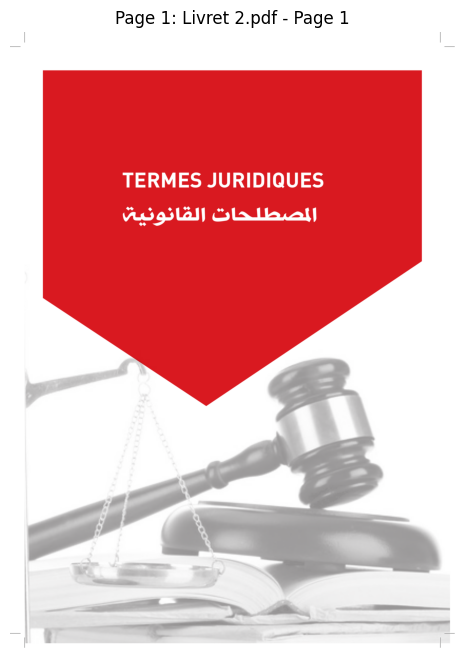


Tesseract (41 chars, 18 Arabic):
------------------------------------------------------------
TERMES JURIDIQUES المصطلحات القانونيض | L

VLM Corrected (37 chars, 18 Arabic):
------------------------------------------------------------
TERMES JURIDIQUES المصطلحات القانونية




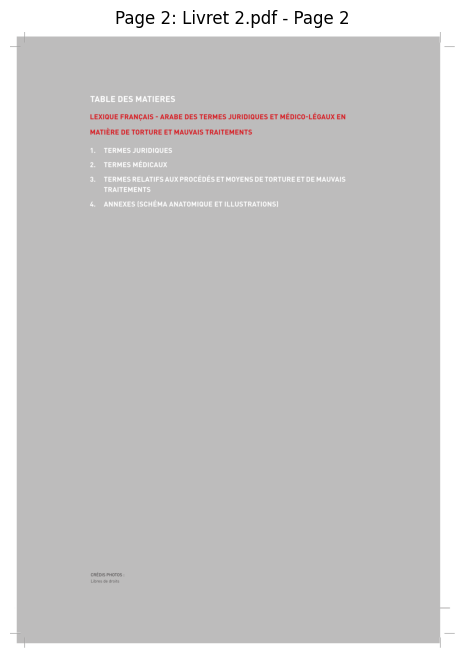


Tesseract (160 chars, 20 Arabic):
------------------------------------------------------------
1 ااذلكا دغط عطاقم ES 1. TERMES JURIDIQUES 2. TE 20e V0 3. TERMES RELATIFS AUX PROCÉDÉS ET MOYENS DE TORTURE ET DE MAUVAIS LL 4. رملللا EL ENT ITU ER UE te) TS]

VLM Corrected (294 chars, 0 Arabic):
------------------------------------------------------------
TABLE DES MATIERES LEXIQUE FRANÇAIS - ARABE DES TERMES JURIDIQUES ET MÉDICO-LÉGAUX EN MATIÈRE DE TORTURE ET MAUVAIS TRAITEMENTS 1. TERMES JURIDIQUES 2. TERMES MÉDICAUX 3. TERMES RELATIFS AUX PROCÉDÉS ET MOYENS DE TORTURE ET DE MAUVAIS TRAITEMENTS 4. ANNEXES (SCHÉMA ANATOMIQUE ET ILLUSTRATIONS)




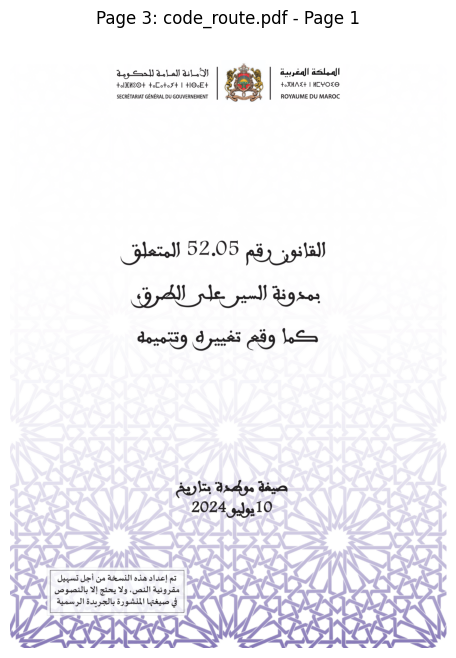


Tesseract (95 chars, 53 Arabic):
------------------------------------------------------------
القانوز رقم 52.05 المتعلق كما وقع تغييرق وتتميمة صيغة موؤمدة بتاريخ ss 10 2024 LOGE ا LB MSA AS

VLM Corrected (104 chars, 76 Arabic):
------------------------------------------------------------
القانون رقم 52.05 المتعلق بمحونة السير على الصرق كما وقع تغييره وتتميمة صيغة موؤمدة بتاريخ 10 يوليو 2024




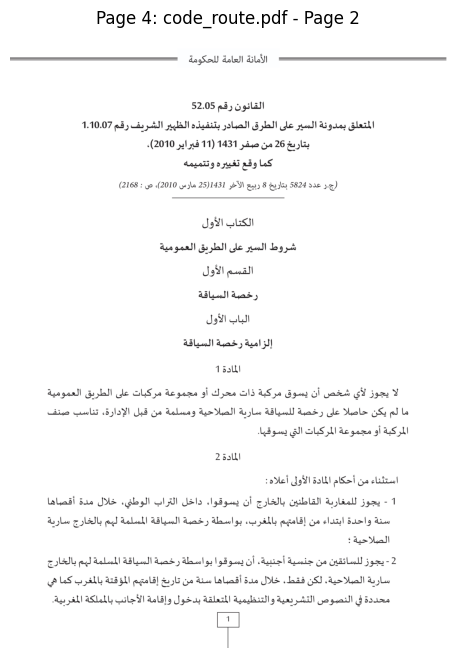


Tesseract (921 chars, 702 Arabic):
------------------------------------------------------------
القانون رقم 52.05 المتعلق بمدونة السير على الطرق الصادر بتنفيذه الظبير الشريف رقم 1.10.07 بتاريخ 26 من صفر 1431 (11 فبراير 2010( كما وقع تغييره وتتميمه لج.د عدد 5824 بتاريخ 6 رسع الاخر 25(1431 مارس 2010( : 2168) الكتاب الاول شروط السير على الطريق العمومية القسم الاول رخصة السياقة الباب الاول الزامية رخصة السياقة المادة 1 ما لم يكن حاصلا على رخصة للسياقة سارية الصلاحية ومسلمة من قبل الادارة. تناسب صنف المركبة او مجموعة المركبات التي يسوقها. المادة 2 استثناء من احكام المادة الاولى اعلاه : 1 - يجوز للمغارية القاطنين بالخارج ان يسوقواء داخل التراب الوطني. خلال مدة اقصاها سنة واحدة ابتداء من اقامهم بالمغرب. بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية ؛ 2- يجوز للسائقين من جنسية اجنبية. ان يسوقوا بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية, لكن فقط. خلال مدة اقصاها سنة من ت
... (121 more chars)

VLM Corrected (1003 chars, 765 Arabic):
----------------------------------------

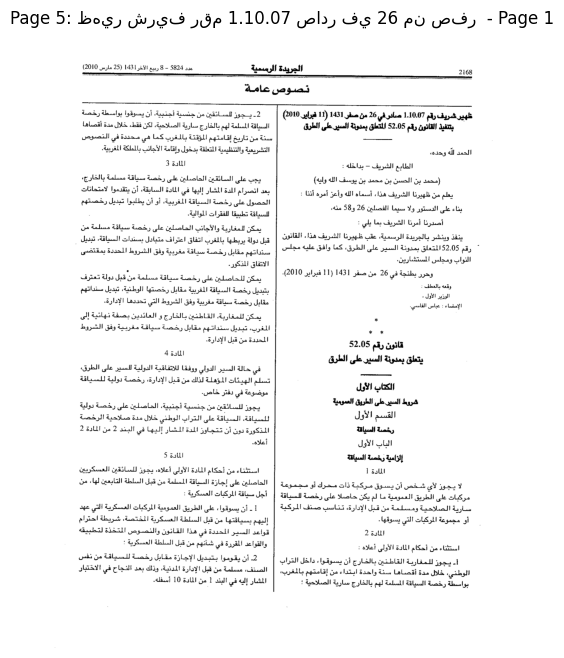


Tesseract (3190 chars, 2437 Arabic):
------------------------------------------------------------
268 الجريدة الرسمية عدد 5824 - 8 ربيع الاخر ا 143 (25 مارس 2010) om ظهيرشريف رقم 1.10.07 صادرفي 26 من صقن 1431 (11 قبراين 2010) 2 يجوز للسائقين من جنسية اجنبية: ان يسوقوا بواسطة رخصة بتنفيذ القانون رقم 5 المتعلق بمدونة السير على الطرق السياقة المسلمة لهم بالخارج سارية الصلاحية, لكن فقط. خلال مدة اقصاها “0 سنة من تاريخ اقامتهم المؤقتة بالمغرب كما هي محددة في النصوص الحمد لله وحدة. التشريعية والتنظيمية المتعلقة بدخول واقامة الاجانب بالمملكة المغربية. الطايع الشريف - بداخله : المادة 3 (محمد بن الحسن بن محمد بن يوسف الله وليه) يجب على السائقين الحاصلين على رخصة سياقة مسلمة بالخارج, يعلم من ظهيرنا الشريف هذاء اسماه الله واعز امره اثنا : بعد اتنصرام المدة المشار اليها في المادة السابقة, ان يتقدموا لامتحانات بناء على الد تور ولا سيما الفصلين 26 و58 منه. الحصول على رخصة السياقة المغربية, اى ان يطل
... (2390 more chars)

VLM Corrected (1790 chars, 1334 Arabic):
------------------------------------

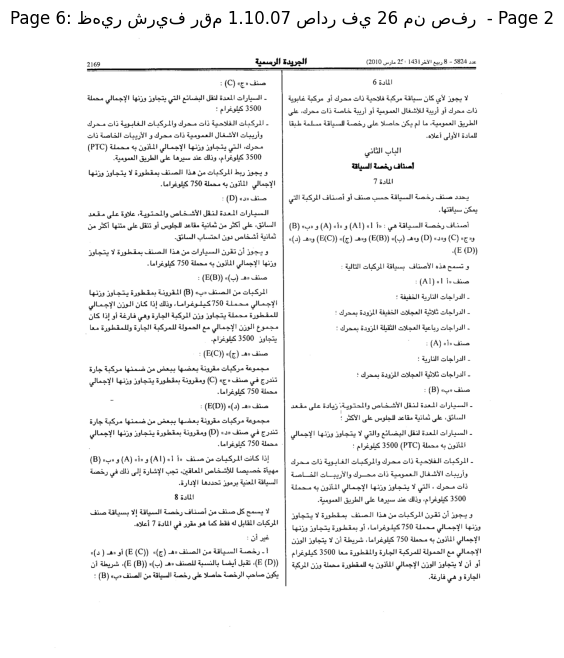


Tesseract (3355 chars, 2400 Arabic):
------------------------------------------------------------
عدد 5824 - 8 ربيع الاخر 1431 25١ مارس 2010) الجريدة الرسمية 2169 المادة 6 صنف «ج» (0): لا يجوز لاي كان سياقة مركبة فلاحية ذات محرك او مركبة غابوية السيارات المعدة لنقل اليضائع التي يتجاوز وزنها الاجمالي محملة ذات محرك او اريبة للاشغال العمومية او اريبة خاصة ذات محرك؛ على 0 كيلوغرام : الطريق العمومية, ما لم يكن حاصلا على رخصة للسياقة مسلمة طبقا المركبات الفلاحية ذات محرك والمركبات الغابوية ذات محرك للمادة الاولى اعلاه. واريبات الاشغال العمومية ذات محرك و الاريبات الخاصة ذات AI LUI محرك. التي يتجاوز وزنها الاجمالي الماذون به محملة (8160) اللي 0 كيلوغرام. وذلك عند سيرها على الطريق العمومية. اصناف رخصة السياقة و يجوز ريط المركبات من هذا الصنف بمقطورة لا يتجاوز وزنها المادة 7 الاجمالي الماذون به محملة 750 كيلوغراما. يحدد صنف رخصة السياقة حسب صنق او اصناف المركبة الت (D) «sas : gi - = 2 à يمكن س
... (2555 more chars)

VLM Corrected (4338 chars, 2655 Arabic):
------------------------------------

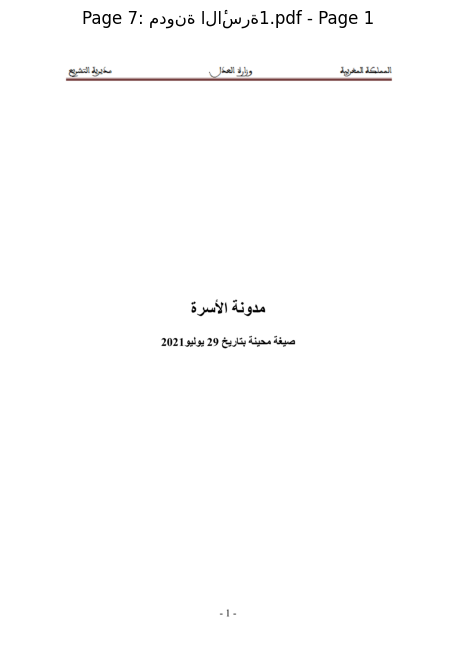


Tesseract (94 chars, 70 Arabic):
------------------------------------------------------------
المملكة المغريية وزارة العذال. مذيرية التشريع مدونة الاسرة صيغة محينة بتاريخ 29 يوليو1 202 -1-

VLM Corrected (94 chars, 69 Arabic):
------------------------------------------------------------
المملكة المغربية وزارة العمال مذروة التشريع مدونة الاسرة صيغة محينة بتاريخ 29 يوليو 2021 - 1 -




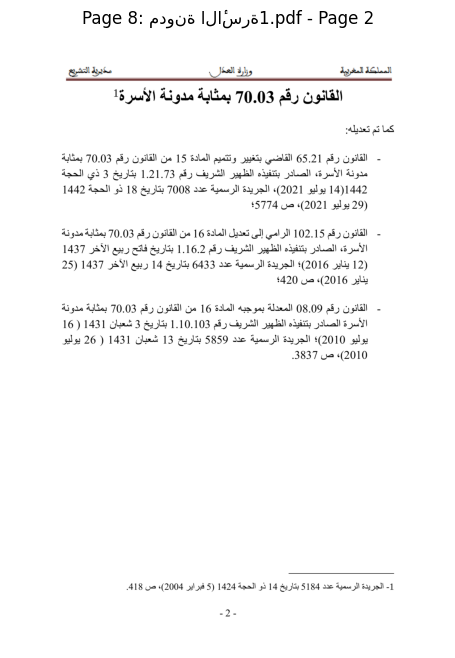


Tesseract (907 chars, 549 Arabic):
------------------------------------------------------------
المملكة المغريبة وزارة العذال. مكيرية التشريع القانون رقم 70.03 بمثابة مدونة الاسرة1 كما تم تعديله: - القانون رقم 65.21 القاضي بتغيير وتتميم المادة 15 من القانون رقم 70.03 بمثابة مدونة الاسرة, الصادر بتنفيذه الظهير الشريف رقم 1.21.73 بتاريخ 3 ذي الحجة 2 يوليو 2021). الجريدة الرسمية عدد 7008 بتاريخ 18 ذو الحجة 1442 (29 يوليو 2021)» ص 45774 - القانون رقم 102.15 الرامي الى تعديل المادة 16 من القانون رقم 70.03 بمثابة مدونة الاسرة» الصادر بتنفيذه الظهير الشريف رقم 1.16.2 بتاريخ فاتح ربيع الاخر 1437 (12 يناير 2016)؛ الجريدة الرسمية عدد 6433 بتاريخ 14 ربيع الاخر 1437 (25 يناير 2016)» ص 420؛ - القانون رقم 08.09 المعدلة بموجبه المادة 16 من القانون رقم 70.03 بمثابة مدونة الاسرة الصادر بتنفيذه الظهير الشريف رقم 1.10.103 بتاريخ 3 شعبان 1431 ( 16 يوليو 2010)؛ الجريدة الرسمية عدد 5859 بتاريخ 13 شعبان 14
... (107 more chars)

VLM Corrected (909 chars, 555 Arabic):
-----------------------------------------

In [11]:
for idx, sample in enumerate(vlm_test_pages):
    # Show image
    plt.figure(figsize=(10, 8))
    plt.imshow(sample["image"])
    plt.axis('off')
    plt.title(f"Page {idx+1}: {sample['source'][:40]} - Page {sample['page_num']}")
    plt.show()

    # Print texts
    for label, key in [("Tesseract", "tess_text"), ("VLM Corrected", "vlm_corrected")]:
        text = sample.get(key, "")
        arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
        print(f"\n{label} ({len(text)} chars, {arabic} Arabic):")
        print("-" * 60)
        print(text[:800])
        if len(text) > 800:
            print(f"... ({len(text)-800} more chars)")
    print("\n" + "=" * 80 + "\n")

In [ ]:
# ============================================
# Free GPU memory
# ============================================
import gc
import torch

print("Unloading previous model...")
try:
    del model
except:
    pass
try:
    del smol_model
except:
    pass
try:
    del molmo_model
except:
    pass
gc.collect()
torch.cuda.empty_cache()
print("GPU memory freed.")

In [15]:
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info

QWEN2VL_ID = "Qwen/Qwen2-VL-2B-Instruct"

print(f"Loading {QWEN2VL_ID}...")
start = time.time()

# Load model in bfloat16 - 2B fits comfortably in T4
qwen2vl_model = Qwen2VLForConditionalGeneration.from_pretrained(
    QWEN2VL_ID,
    torch_dtype=torch.bfloat16,
    device_map="auto",
)

# Set min/max pixels for reasonable memory usage
qwen2vl_processor = AutoProcessor.from_pretrained(
    QWEN2VL_ID,
    min_pixels=256 * 28 * 28,   # ~200K pixels minimum
    max_pixels=1024 * 28 * 28,  # ~800K pixels maximum
)

print(f"Qwen2-VL-2B loaded in {time.time() - start:.1f}s on {qwen2vl_model.device}")

Loading Qwen/Qwen2-VL-2B-Instruct...


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Qwen2-VL-2B loaded in 88.1s on cuda:0


In [16]:
def qwen2vl_correct_ocr(image, ocr_text):
    """Correct OCR with Qwen2-VL-2B-Instruct."""
    image = resize_image(image)  # reuse same resize function
    if len(ocr_text) > 3000:
        ocr_text = ocr_text[:3000] + "\n... [truncated]"

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": (
                    "You are shown a Moroccan legal document page and its OCR-extracted text. "
                    "The OCR may contain errors: misread characters, merged words, missing diacritics, "
                    "wrong article numbers, headers mixed into body text.\n\n"
                    "OCR TEXT:\n"
                    f"{ocr_text}\n\n"
                    "Compare the OCR text with the image. Correct all errors you can visually verify. "
                    "Preserve all legal terms, article numbers, and structure exactly. "
                    "Do not add or remove content that is not visible in the image. "
                    "Output only the corrected text, no extra commentary."
                )},
            ],
        }
    ]

    # Prepare inputs
    text = qwen2vl_processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = qwen2vl_processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    ).to(qwen2vl_model.device)

    # Generate
    with torch.no_grad():
        generated_ids = qwen2vl_model.generate(**inputs, max_new_tokens=2048)

    # Extract only generated tokens
    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output = qwen2vl_processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    # Clean up
    del inputs, generated_ids, generated_ids_trimmed
    torch.cuda.empty_cache()

    return output.strip()


print("Qwen2-VL correction function ready.")

Qwen2-VL correction function ready.


In [17]:
print("Running Qwen2-VL correction on Tesseract output...")
for i, page in enumerate(vlm_test_pages):
    ocr_input = page["tess_text"]
    print(f"  Page {i+1}: {page['source'][:30]} p{page['page_num']} ({len(ocr_input)} chars input)")
    start = time.time()
    try:
        corrected = qwen2vl_correct_ocr(page["image"], ocr_input)
        page["qwen2vl_corrected"] = basic_clean(corrected)
        page["qwen2vl_corr_time"] = time.time() - start
        print(f"    Output: {len(page['qwen2vl_corrected'])} chars, {page['qwen2vl_corr_time']:.1f}s")
    except Exception as e:
        print(f"    Error: {e}")
        page["qwen2vl_corrected"] = ""
        page["qwen2vl_corr_time"] = 0
    torch.cuda.empty_cache()

print("Qwen2-VL correction complete.")

Running Qwen2-VL correction on Tesseract output...
  Page 1: Livret 2.pdf p1 (41 chars input)
    Output: 41 chars, 7.7s
  Page 2: Livret 2.pdf p2 (160 chars input)
    Output: 166 chars, 10.6s
  Page 3: code_route.pdf p1 (95 chars input)
    Output: 95 chars, 10.0s
  Page 4: code_route.pdf p2 (921 chars input)
    Output: 921 chars, 31.6s
  Page 5: ظهير شريف رقم 1.10.07 صادر في  p1 (3190 chars input)
    Output: 2658 chars, 65.9s
  Page 6: ظهير شريف رقم 1.10.07 صادر في  p2 (3355 chars input)
    Output: 2503 chars, 64.4s
  Page 7: مدونة الأسرة1.pdf p1 (94 chars input)
    Output: 90 chars, 10.3s
  Page 8: مدونة الأسرة1.pdf p2 (907 chars input)
    Output: 907 chars, 27.9s
Qwen2-VL correction complete.


In [18]:
def extract_articles(text):
    matches = re.findall(r'المادة\s+(\d+)', text)
    return set(matches)

print("Article number preservation check:")
for page in vlm_test_pages:
    page["tess_articles"] = extract_articles(page.get("tess_text", ""))
    page["qwen_articles"] = extract_articles(page.get("vlm_corrected", ""))
    page["qwen2vl_articles"] = extract_articles(page.get("qwen2vl_corrected", ""))

    tess_art = sorted(page["tess_articles"])
    qwen_art = sorted(page["qwen_articles"])
    qwen2vl_art = sorted(page["qwen2vl_articles"])

    print(f"\n{page['source'][:30]} p{page['page_num']}:")
    print(f"  Tesseract:      {tess_art}")
    print(f"  Qwen2.5-VL:     {qwen_art}")
    print(f"  Qwen2-VL-2B:    {qwen2vl_art}")

    # Qwen2.5 diffs
    missing_q = page["tess_articles"] - page["qwen_articles"]
    added_q = page["qwen_articles"] - page["tess_articles"]
    if missing_q: print(f"    Qwen2.5-VL: LOST {sorted(missing_q)}")
    if added_q: print(f"    Qwen2.5-VL: ADDED {sorted(added_q)}")

    # Qwen2-VL diffs
    missing_q2 = page["tess_articles"] - page["qwen2vl_articles"]
    added_q2 = page["qwen2vl_articles"] - page["tess_articles"]
    if missing_q2: print(f"    Qwen2-VL: LOST {sorted(missing_q2)}")
    if added_q2: print(f"    Qwen2-VL: ADDED {sorted(added_q2)}")

Article number preservation check:

Livret 2.pdf p1:
  Tesseract:      []
  Qwen2.5-VL:     []
  Qwen2-VL-2B:    []

Livret 2.pdf p2:
  Tesseract:      []
  Qwen2.5-VL:     []
  Qwen2-VL-2B:    []

code_route.pdf p1:
  Tesseract:      []
  Qwen2.5-VL:     []
  Qwen2-VL-2B:    []

code_route.pdf p2:
  Tesseract:      ['1', '2']
  Qwen2.5-VL:     ['1', '2']
  Qwen2-VL-2B:    ['1', '2']

ظهير شريف رقم 1.10.07 صادر في  p1:
  Tesseract:      ['1', '10', '2', '3', '4', '5']
  Qwen2.5-VL:     ['1', '2', '4', '5']
  Qwen2-VL-2B:    ['2', '3', '4']
    Qwen2.5-VL: LOST ['10', '3']
    Qwen2-VL: LOST ['1', '10', '5']

ظهير شريف رقم 1.10.07 صادر في  p2:
  Tesseract:      ['6', '7', '8']
  Qwen2.5-VL:     ['6', '7']
  Qwen2-VL-2B:    ['6', '7', '8']
    Qwen2.5-VL: LOST ['8']

مدونة الأسرة1.pdf p1:
  Tesseract:      []
  Qwen2.5-VL:     []
  Qwen2-VL-2B:    []

مدونة الأسرة1.pdf p2:
  Tesseract:      ['15', '16']
  Qwen2.5-VL:     ['15', '16']
  Qwen2-VL-2B:    ['15', '16']


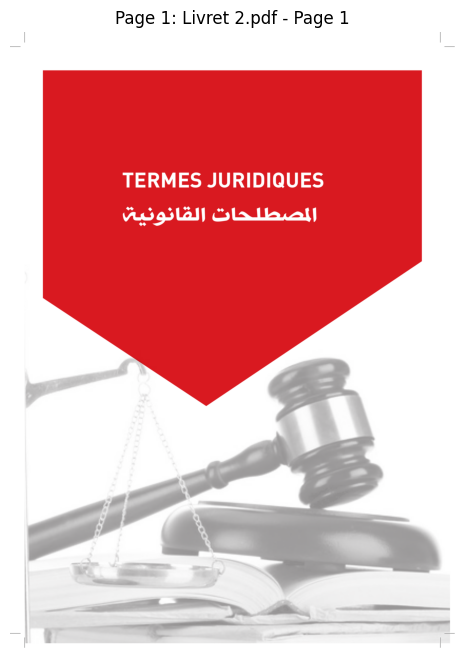


Tesseract (41 chars, 18 Arabic):
------------------------------------------------------------
TERMES JURIDIQUES المصطلحات القانونيض | L

Qwen2.5-VL corrected (37 chars, 18 Arabic):
------------------------------------------------------------
TERMES JURIDIQUES المصطلحات القانونية

Qwen2-VL-2B corrected (41 chars, 18 Arabic):
------------------------------------------------------------
TERMES JURIDIQUES المصطلحات القانونيض | L




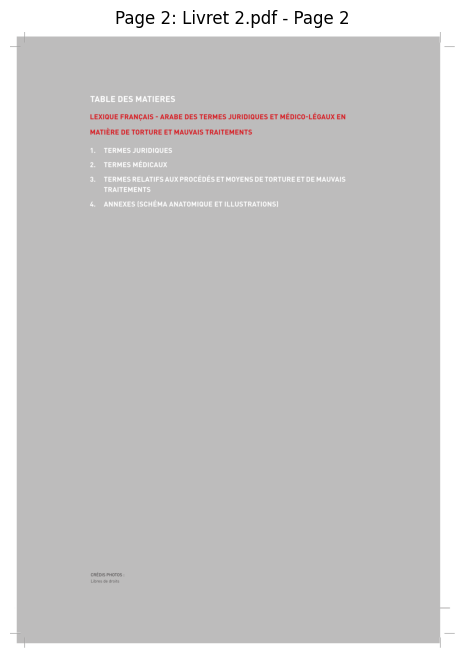


Tesseract (160 chars, 20 Arabic):
------------------------------------------------------------
1 ااذلكا دغط عطاقم ES 1. TERMES JURIDIQUES 2. TE 20e V0 3. TERMES RELATIFS AUX PROCÉDÉS ET MOYENS DE TORTURE ET DE MAUVAIS LL 4. رملللا EL ENT ITU ER UE te) TS]

Qwen2.5-VL corrected (294 chars, 0 Arabic):
------------------------------------------------------------
TABLE DES MATIERES LEXIQUE FRANÇAIS - ARABE DES TERMES JURIDIQUES ET MÉDICO-LÉGAUX EN MATIÈRE DE TORTURE ET MAUVAIS TRAITEMENTS 1. TERMES JURIDIQUES 2. TERMES MÉDICAUX 3. TERMES RELATIFS AUX PROCÉDÉS ET MOYENS DE TORTURE ET DE MAUVAIS TRAITEMENTS 4. ANNEXES (SCHÉMA ANATOMIQUE ET ILLUSTRATIONS)

Qwen2-VL-2B corrected (166 chars, 0 Arabic):
------------------------------------------------------------
1. TERMES JURIDIQUES 2. TERMES MÉDICAUX 3. TERMES RELATIFS AUX PROCÉDÉS ET MOYENS DE TORTURE ET DE MAUVAIS TRAITEMENTS 4. ANNEXES (SCHÉMA ANATOMIQUE ET ILLUSTRATIONS)




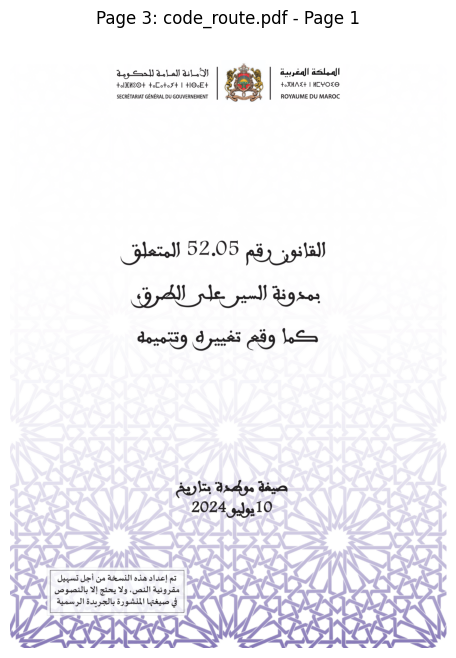


Tesseract (95 chars, 53 Arabic):
------------------------------------------------------------
القانوز رقم 52.05 المتعلق كما وقع تغييرق وتتميمة صيغة موؤمدة بتاريخ ss 10 2024 LOGE ا LB MSA AS

Qwen2.5-VL corrected (104 chars, 76 Arabic):
------------------------------------------------------------
القانون رقم 52.05 المتعلق بمحونة السير على الصرق كما وقع تغييره وتتميمة صيغة موؤمدة بتاريخ 10 يوليو 2024

Qwen2-VL-2B corrected (95 chars, 53 Arabic):
------------------------------------------------------------
القانوز رقم 52.05 المتعلق كما وقع تغييرق وتتميمة صيغة موؤمدة بتاريخ ss 10 2024 LOGE ا LB MSA AS




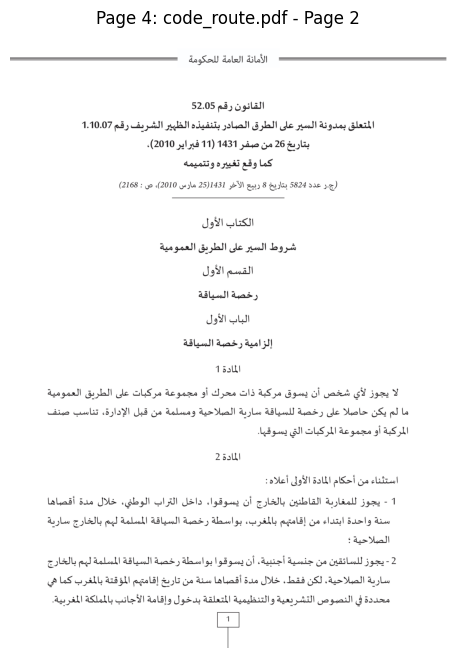


Tesseract (921 chars, 702 Arabic):
------------------------------------------------------------
القانون رقم 52.05 المتعلق بمدونة السير على الطرق الصادر بتنفيذه الظبير الشريف رقم 1.10.07 بتاريخ 26 من صفر 1431 (11 فبراير 2010( كما وقع تغييره وتتميمه لج.د عدد 5824 بتاريخ 6 رسع الاخر 25(1431 مارس 2010( : 2168) الكتاب الاول شروط السير على الطريق العمومية القسم الاول رخصة السياقة الباب الاول الزامية رخصة السياقة المادة 1 ما لم يكن حاصلا على رخصة للسياقة سارية الصلاحية ومسلمة من قبل الادارة. تناسب صنف المركبة او مجموعة المركبات التي يسوقها. المادة 2 استثناء من احكام المادة الاولى اعلاه : 1 - يجوز للمغارية القاطنين بالخارج ان يسوقواء داخل التراب الوطني. خلال مدة اقصاها سنة واحدة ابتداء من اقامهم بالمغرب. بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية ؛ 2- يجوز للسائقين من جنسية اجنبية. ان يسوقوا بواسطة رخصة السياقة المسلمة لهم بالخارج سارية الصلاحية, لكن فقط. خلال مدة اقصاها سنة من ت
... (121 more chars)

Qwen2.5-VL corrected (1003 chars, 765 Arabic):
---------------------------------

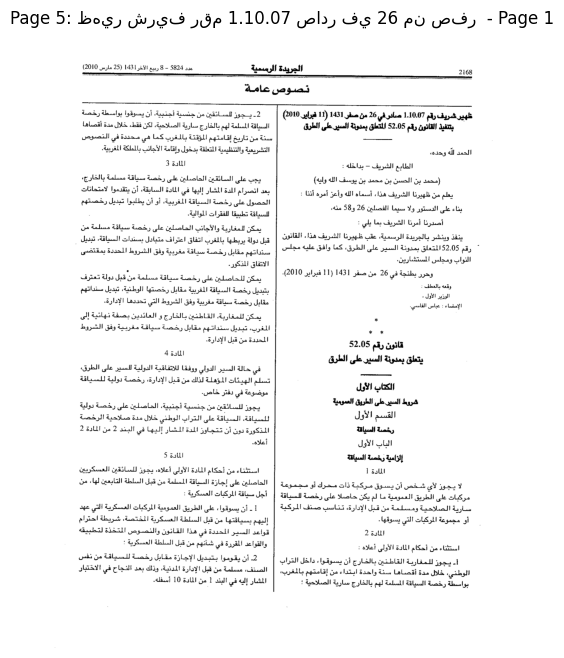


Tesseract (3190 chars, 2437 Arabic):
------------------------------------------------------------
268 الجريدة الرسمية عدد 5824 - 8 ربيع الاخر ا 143 (25 مارس 2010) om ظهيرشريف رقم 1.10.07 صادرفي 26 من صقن 1431 (11 قبراين 2010) 2 يجوز للسائقين من جنسية اجنبية: ان يسوقوا بواسطة رخصة بتنفيذ القانون رقم 5 المتعلق بمدونة السير على الطرق السياقة المسلمة لهم بالخارج سارية الصلاحية, لكن فقط. خلال مدة اقصاها “0 سنة من تاريخ اقامتهم المؤقتة بالمغرب كما هي محددة في النصوص الحمد لله وحدة. التشريعية والتنظيمية المتعلقة بدخول واقامة الاجانب بالمملكة المغربية. الطايع الشريف - بداخله : المادة 3 (محمد بن الحسن بن محمد بن يوسف الله وليه) يجب على السائقين الحاصلين على رخصة سياقة مسلمة بالخارج, يعلم من ظهيرنا الشريف هذاء اسماه الله واعز امره اثنا : بعد اتنصرام المدة المشار اليها في المادة السابقة, ان يتقدموا لامتحانات بناء على الد تور ولا سيما الفصلين 26 و58 منه. الحصول على رخصة السياقة المغربية, اى ان يطل
... (2390 more chars)

Qwen2.5-VL corrected (1790 chars, 1334 Arabic):
-----------------------------

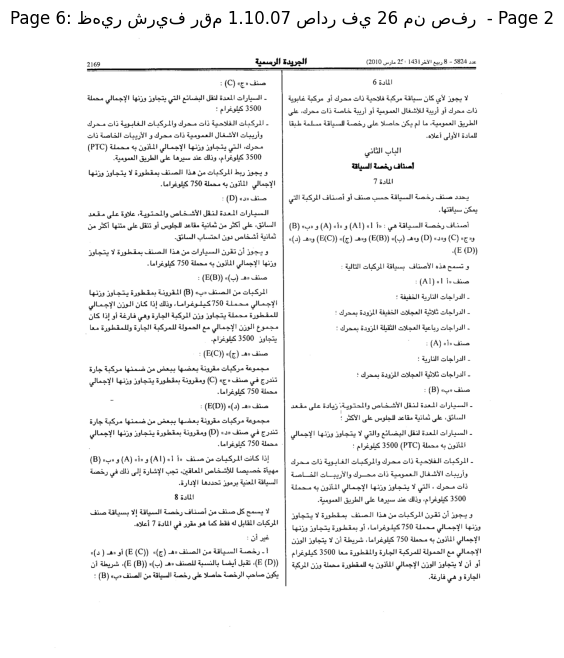


Tesseract (3355 chars, 2400 Arabic):
------------------------------------------------------------
عدد 5824 - 8 ربيع الاخر 1431 25١ مارس 2010) الجريدة الرسمية 2169 المادة 6 صنف «ج» (0): لا يجوز لاي كان سياقة مركبة فلاحية ذات محرك او مركبة غابوية السيارات المعدة لنقل اليضائع التي يتجاوز وزنها الاجمالي محملة ذات محرك او اريبة للاشغال العمومية او اريبة خاصة ذات محرك؛ على 0 كيلوغرام : الطريق العمومية, ما لم يكن حاصلا على رخصة للسياقة مسلمة طبقا المركبات الفلاحية ذات محرك والمركبات الغابوية ذات محرك للمادة الاولى اعلاه. واريبات الاشغال العمومية ذات محرك و الاريبات الخاصة ذات AI LUI محرك. التي يتجاوز وزنها الاجمالي الماذون به محملة (8160) اللي 0 كيلوغرام. وذلك عند سيرها على الطريق العمومية. اصناف رخصة السياقة و يجوز ريط المركبات من هذا الصنف بمقطورة لا يتجاوز وزنها المادة 7 الاجمالي الماذون به محملة 750 كيلوغراما. يحدد صنف رخصة السياقة حسب صنق او اصناف المركبة الت (D) «sas : gi - = 2 à يمكن س
... (2555 more chars)

Qwen2.5-VL corrected (4338 chars, 2655 Arabic):
-----------------------------

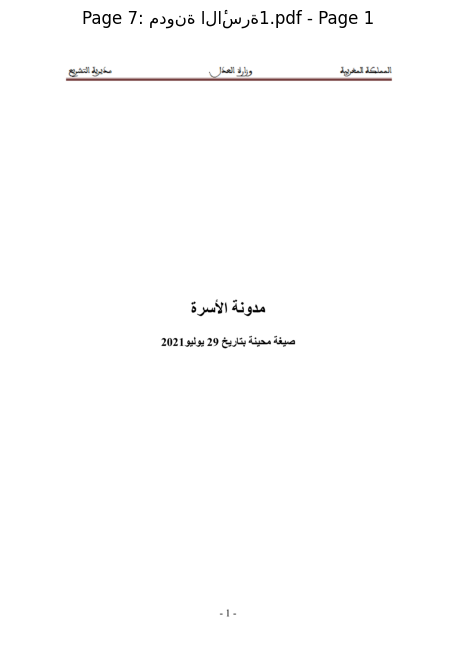


Tesseract (94 chars, 70 Arabic):
------------------------------------------------------------
المملكة المغريية وزارة العذال. مذيرية التشريع مدونة الاسرة صيغة محينة بتاريخ 29 يوليو1 202 -1-

Qwen2.5-VL corrected (94 chars, 69 Arabic):
------------------------------------------------------------
المملكة المغربية وزارة العمال مذروة التشريع مدونة الاسرة صيغة محينة بتاريخ 29 يوليو 2021 - 1 -

Qwen2-VL-2B corrected (90 chars, 70 Arabic):
------------------------------------------------------------
المملكة المغريية وزارة العذال. مذيرية التشريع مدونة الاسرة صيغة محينة بتاريخ 29 يوليو1 202




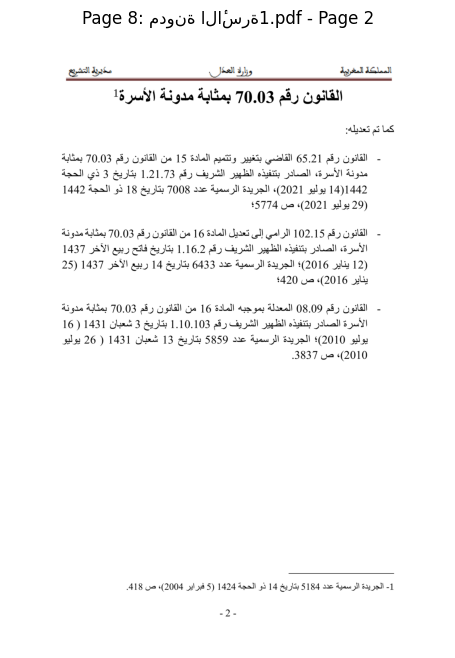


Tesseract (907 chars, 549 Arabic):
------------------------------------------------------------
المملكة المغريبة وزارة العذال. مكيرية التشريع القانون رقم 70.03 بمثابة مدونة الاسرة1 كما تم تعديله: - القانون رقم 65.21 القاضي بتغيير وتتميم المادة 15 من القانون رقم 70.03 بمثابة مدونة الاسرة, الصادر بتنفيذه الظهير الشريف رقم 1.21.73 بتاريخ 3 ذي الحجة 2 يوليو 2021). الجريدة الرسمية عدد 7008 بتاريخ 18 ذو الحجة 1442 (29 يوليو 2021)» ص 45774 - القانون رقم 102.15 الرامي الى تعديل المادة 16 من القانون رقم 70.03 بمثابة مدونة الاسرة» الصادر بتنفيذه الظهير الشريف رقم 1.16.2 بتاريخ فاتح ربيع الاخر 1437 (12 يناير 2016)؛ الجريدة الرسمية عدد 6433 بتاريخ 14 ربيع الاخر 1437 (25 يناير 2016)» ص 420؛ - القانون رقم 08.09 المعدلة بموجبه المادة 16 من القانون رقم 70.03 بمثابة مدونة الاسرة الصادر بتنفيذه الظهير الشريف رقم 1.10.103 بتاريخ 3 شعبان 1431 ( 16 يوليو 2010)؛ الجريدة الرسمية عدد 5859 بتاريخ 13 شعبان 14
... (107 more chars)

Qwen2.5-VL corrected (909 chars, 555 Arabic):
----------------------------------

In [19]:
for idx, sample in enumerate(vlm_test_pages):
    plt.figure(figsize=(10, 8))
    plt.imshow(sample["image"])
    plt.axis('off')
    plt.title(f"Page {idx+1}: {sample['source'][:40]} - Page {sample['page_num']}")
    plt.show()

    for label, key in [
        ("Tesseract", "tess_text"),
        ("Qwen2.5-VL corrected", "vlm_corrected"),
        ("Qwen2-VL-2B corrected", "qwen2vl_corrected"),
    ]:
        text = sample.get(key, "")
        arabic = sum(1 for c in text if '\u0600' <= c <= '\u06ff')
        print(f"\n{label} ({len(text)} chars, {arabic} Arabic):")
        print("-" * 60)
        print(text[:800])
        if len(text) > 800:
            print(f"... ({len(text)-800} more chars)")
    print("\n" + "=" * 80 + "\n")

In [20]:
print("=" * 80)
print("SUMMARY: Tesseract vs Qwen2.5-VL vs Qwen2-VL-2B")
print("=" * 80)

all_tess = set()
all_qwen = set()
all_qwen2vl = set()
for page in vlm_test_pages:
    all_tess.update(page.get("tess_articles", set()))
    all_qwen.update(page.get("qwen_articles", set()))
    all_qwen2vl.update(page.get("qwen2vl_articles", set()))

print(f"\nTesseract articles:     {sorted(all_tess)}")
print(f"Qwen2.5-VL articles:    {sorted(all_qwen)}")
print(f"Qwen2-VL-2B articles:   {sorted(all_qwen2vl)}")

print("\nPer-page comparison:")
for page in vlm_test_pages:
    print(f"\n{page['source'][:30]} p{page['page_num']}:")
    print(f"  Tesseract:          {len(page['tess_text']):>5} chars, {page['tess_time']:.1f}s")
    print(f"  Qwen2.5-VL corr:    {len(page.get('vlm_corrected','')):>5} chars, {page.get('vlm_corr_time',0):.1f}s")
    print(f"  Qwen2-VL-2B corr:   {len(page.get('qwen2vl_corrected','')):>5} chars, {page.get('qwen2vl_corr_time',0):.1f}s")

# Article preservation
qwen_lost = all_tess - all_qwen
qwen_added = all_qwen - all_tess
qwen2vl_lost = all_tess - all_qwen2vl
qwen2vl_added = all_qwen2vl - all_tess

print("\nArticle number preservation (vs Tesseract):")
print(f"  Qwen2.5-VL:     Lost: {sorted(qwen_lost) if qwen_lost else 'None'}, Added: {sorted(qwen_added) if qwen_added else 'None'}")
print(f"  Qwen2-VL-2B:    Lost: {sorted(qwen2vl_lost) if qwen2vl_lost else 'None'}, Added: {sorted(qwen2vl_added) if qwen2vl_added else 'None'}")

print("\n" + "=" * 80)
print("BENCHMARK COMPLETE")
print("=" * 80)

SUMMARY: Tesseract vs Qwen2.5-VL vs Qwen2-VL-2B

Tesseract articles:     ['1', '10', '15', '16', '2', '3', '4', '5', '6', '7', '8']
Qwen2.5-VL articles:    ['1', '15', '16', '2', '4', '5', '6', '7']
Qwen2-VL-2B articles:   ['1', '15', '16', '2', '3', '4', '6', '7', '8']

Per-page comparison:

Livret 2.pdf p1:
  Tesseract:             41 chars, 2.4s
  Qwen2.5-VL corr:       37 chars, 17.3s
  Qwen2-VL-2B corr:      41 chars, 7.7s

Livret 2.pdf p2:
  Tesseract:            160 chars, 6.8s
  Qwen2.5-VL corr:      294 chars, 27.6s
  Qwen2-VL-2B corr:     166 chars, 10.6s

code_route.pdf p1:
  Tesseract:             95 chars, 4.2s
  Qwen2.5-VL corr:      104 chars, 10.9s
  Qwen2-VL-2B corr:      95 chars, 10.0s

code_route.pdf p2:
  Tesseract:            921 chars, 8.2s
  Qwen2.5-VL corr:     1003 chars, 49.8s
  Qwen2-VL-2B corr:     921 chars, 31.6s

ظهير شريف رقم 1.10.07 صادر في  p1:
  Tesseract:           3190 chars, 22.4s
  Qwen2.5-VL corr:     1790 chars, 99.1s
  Qwen2-VL-2B corr:    265